In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import random
from sklearn.model_selection import train_test_split
from sklearn.neighbors import  KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

In [2]:
student= pd.read_csv('/content/drive/MyDrive/CSV/student_depression_dataset.csv')

In [3]:
student.columns= student.columns.str.lower().str.replace(" ", "_")
student.head()

,id,gender,age,city,profession,academic_pressure,work_pressure,cgpa,study_satisfaction,job_satisfaction,sleep_duration,dietary_habits,degree,have_you_ever_had_suicidal_thoughts_?,work/study_hours,financial_stress,family_history_of_mental_illness,depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,'5-6 hours',Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,'5-6 hours',Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,'Less than 5 hours',Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,'7-8 hours',Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,'5-6 hours',Moderate,M.Tech,Yes,1.0,1.0,No,0


In [4]:
student.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   gender                                 27901 non-null  object 
 2   age                                    27901 non-null  float64
 3   city                                   27901 non-null  object 
 4   profession                             27901 non-null  object 
 5   academic_pressure                      27901 non-null  float64
 6   work_pressure                          27901 non-null  float64
 7   cgpa                                   27901 non-null  float64
 8   study_satisfaction                     27901 non-null  float64
 9   job_satisfaction                       27901 non-null  float64
 10  sleep_duration                         27901 non-null  object 
 11  di

In [5]:
student.replace('?', np.nan, inplace= True)
student= student.apply(pd.to_numeric, errors='coerce')

                         age  academic_pressure  work_pressure      cgpa  \
age                 1.000000          -0.075803       0.002015  0.005056   
academic_pressure  -0.075803           1.000000      -0.022231 -0.022239   
work_pressure       0.002015          -0.022231       1.000000 -0.050896   
cgpa                0.005056          -0.022239      -0.050896  1.000000   
study_satisfaction  0.009235          -0.110988      -0.021145 -0.044062   
job_satisfaction   -0.000432          -0.024945       0.770652 -0.053631   
work/study_hours   -0.032928           0.095970      -0.005468  0.002604   
financial_stress   -0.095026           0.151706       0.001883  0.005885   
depression         -0.226422           0.474835      -0.003351  0.022210   

                    study_satisfaction  job_satisfaction  work/study_hours  \
age                           0.009235         -0.000432         -0.032928   
academic_pressure            -0.110988         -0.024945          0.095970   
work_

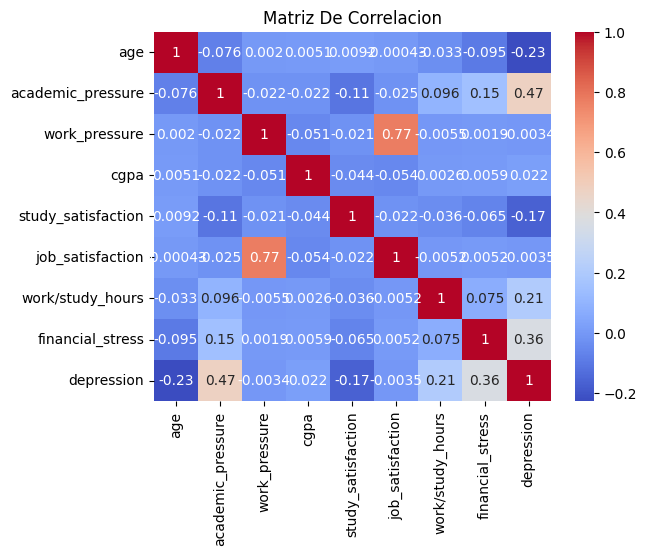

In [9]:
numeric= student[['age', 'academic_pressure', 'work_pressure', 'cgpa', 'study_satisfaction', 'job_satisfaction', 'work/study_hours', 'financial_stress','depression' ]]

corr_matrix= numeric.corr()
print(corr_matrix)

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')

plt.title('Matriz De Correlacion')
plt.show()

In [96]:
numeric.head()

,age,academic_pressure,work_pressure,cgpa,study_satisfaction,job_satisfaction,work/study_hours,financial_stress,depression
0,33.0,5.0,0.0,8.97,2.0,0.0,3.0,1.0,1
1,24.0,2.0,0.0,5.90,5.0,0.0,3.0,2.0,0
2,31.0,3.0,0.0,7.03,5.0,0.0,9.0,1.0,0
3,28.0,3.0,0.0,5.59,2.0,0.0,4.0,5.0,1
4,25.0,4.0,0.0,8.13,3.0,0.0,1.0,1.0,0


In [97]:
con_depresion= numeric[numeric['depression']== 1]
con_depresion.head()

,age,academic_pressure,work_pressure,cgpa,study_satisfaction,job_satisfaction,work/study_hours,financial_stress,depression
0,33.0,5.0,0.0,8.97,2.0,0.0,3.0,1.0,1
3,28.0,3.0,0.0,5.59,2.0,0.0,4.0,5.0,1
8,28.0,3.0,0.0,9.79,1.0,0.0,12.0,3.0,1
9,31.0,2.0,0.0,8.38,3.0,0.0,2.0,5.0,1
10,24.0,3.0,0.0,6.10,3.0,0.0,11.0,1.0,1


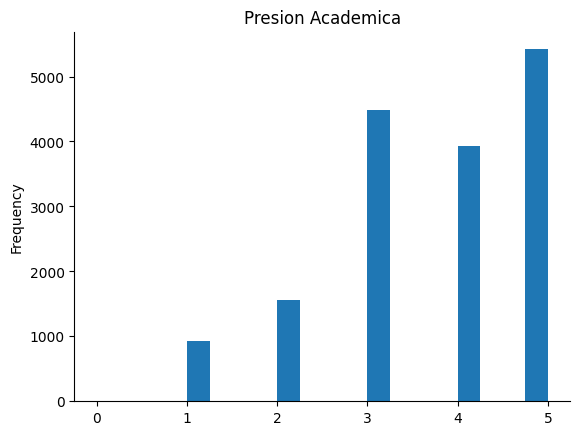

In [98]:
from matplotlib import pyplot as plt
con_depresion['academic_pressure'].plot(kind='hist', bins=20, title='Presion Academica')
plt.gca().spines[['top', 'right',]].set_visible(False)

In [99]:
sin_depresion= numeric[numeric['depression']== 0]
sin_depresion.head()

,age,academic_pressure,work_pressure,cgpa,study_satisfaction,job_satisfaction,work/study_hours,financial_stress,depression
1,24.0,2.0,0.0,5.90,5.0,0.0,3.0,2.0,0
2,31.0,3.0,0.0,7.03,5.0,0.0,9.0,1.0,0
4,25.0,4.0,0.0,8.13,3.0,0.0,1.0,1.0,0
5,29.0,2.0,0.0,5.70,3.0,0.0,4.0,1.0,0
6,30.0,3.0,0.0,9.54,4.0,0.0,1.0,2.0,0


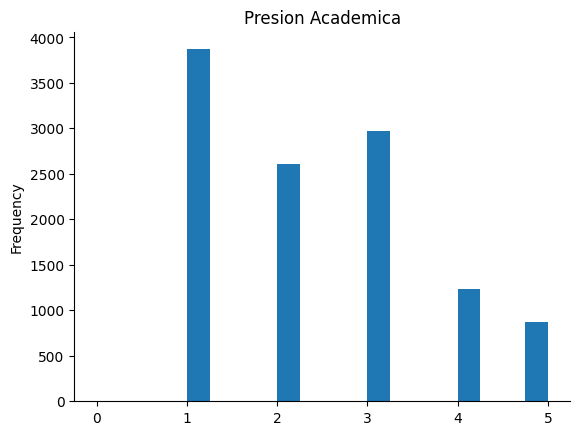

In [100]:
from matplotlib import pyplot as plt
sin_depresion['academic_pressure'].plot(kind='hist', bins=20, title='Presion Academica')
plt.gca().spines[['top', 'right',]].set_visible(False)

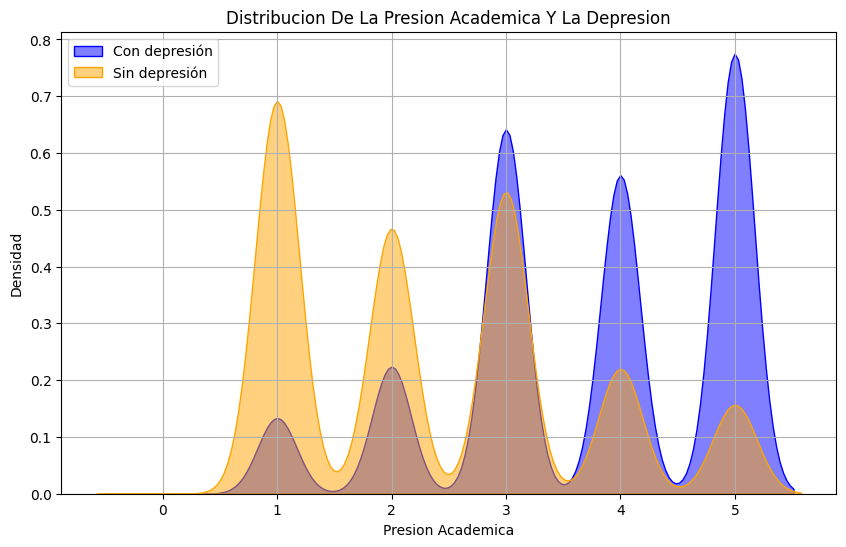

In [101]:
plt.figure(figsize=(10, 6))

sns.kdeplot(data=numeric[numeric['depression'] == 1], x='academic_pressure', label='Con depresión', fill=True, color='blue', alpha=0.5)
sns.kdeplot(data=numeric[numeric['depression'] == 0], x='academic_pressure', label='Sin depresión', fill=True, color='orange', alpha=0.5)

plt.title('Distribucion De La Presion Academica Y La Depresion')
plt.xlabel('Presion Academica')
plt.ylabel('Densidad')
plt.legend()
plt.grid(True)
plt.show()

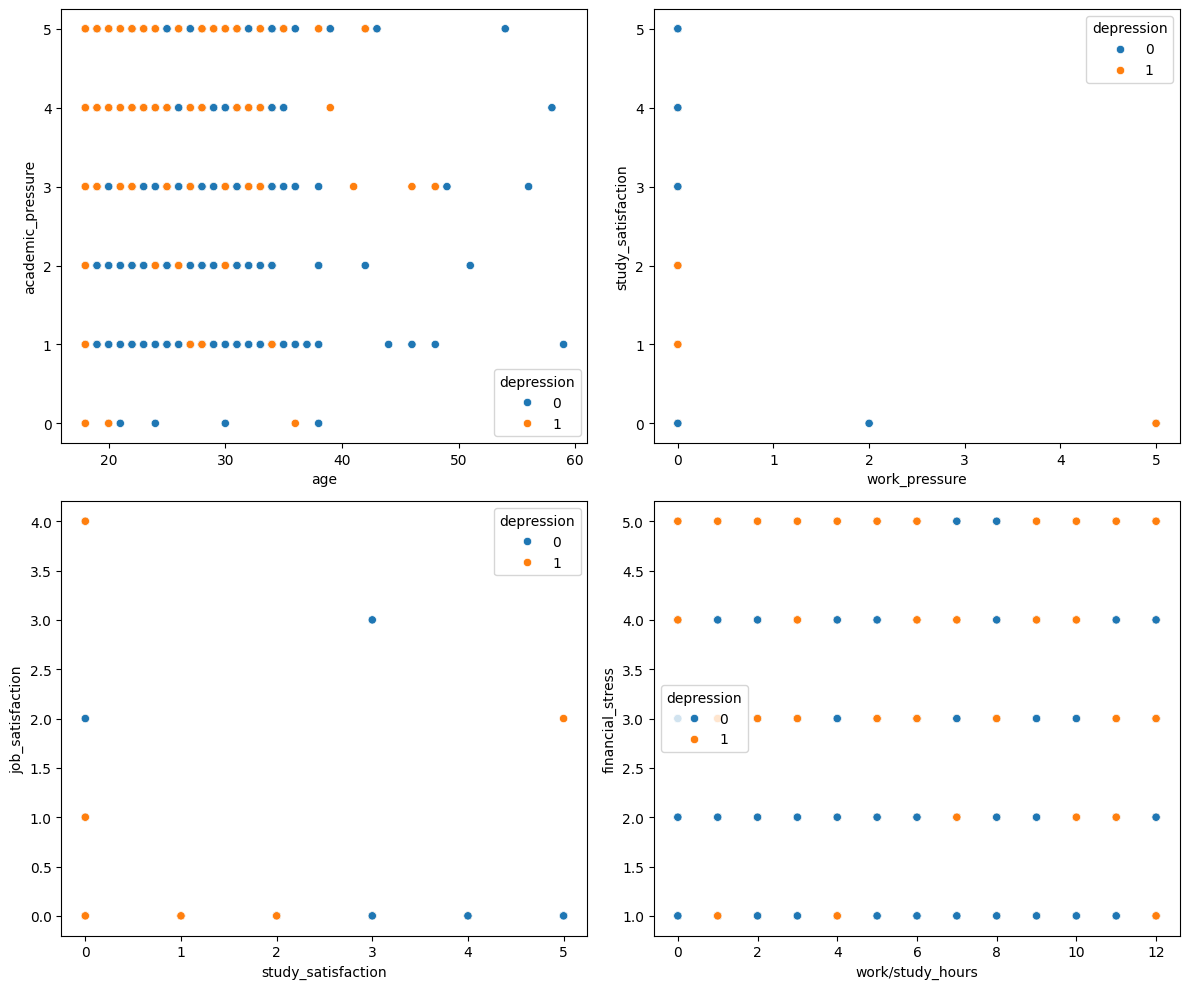

In [102]:
fig, axes= plt.subplots(2, 2, figsize=(12, 10))

sns.scatterplot(data=numeric, x='age', y='academic_pressure', hue='depression', ax= axes[0,0])
sns.scatterplot(data=numeric, x='work_pressure', y='study_satisfaction', hue='depression', ax= axes[0, 1])
sns.scatterplot(data=numeric, x='study_satisfaction', y='job_satisfaction', hue='depression', ax= axes[1,0])
sns.scatterplot(data=numeric, x='work/study_hours', y='financial_stress', hue='depression', ax= axes[1,1])

plt.tight_layout()
plt.show()

In [121]:
from sklearn.preprocessing import LabelEncoder
label_encoder= LabelEncoder()
numeric['depression_encoded', 'age_escoded']= label_encoder.fit_transform(numeric['depression']['age'])
print(numeric[['depression', 'depression_encoded']].head())
original_clases= label_encoder.inverse_transform([0, 1])
print(f"Clases Originales: {original_clases}")

KeyError: ('depression', 'age')

In [104]:
print(numeric['depression_encoded'].value_counts())

depression_encoded
1    16336
0    11565
Name: count, dtype: int64


In [105]:
X= numeric.drop(columns=["depression_encoded"])
y= numeric["depression_encoded"]

In [106]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(22320, 9) (5581, 9) (22320,) (5581,)


In [107]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.impute import SimpleImputer

Knn = KNeighborsClassifier(n_neighbors=3)

X_train= X_train.dropna()
y_train= y_train[X_train.index]

X_test= X_test.dropna()
y_test= y_test[X_test.index]

Knn.fit(X_train, y_train)


y_pred= Knn.predict(X_test)

In [108]:
accuracy= accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")

print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 92.96%
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.90      0.91      2343
           1       0.93      0.95      0.94      3238

    accuracy                           0.93      5581
   macro avg       0.93      0.93      0.93      5581
weighted avg       0.93      0.93      0.93      5581



In [109]:
random_index= np.random.choice(X_test.index)
random_data= X_test.loc[random_index]

predicted_class= Knn.predict([random_data]) [0]
real_class_student= numeric.loc[numeric.index== random_index, "depression_encoded"].values[0]
real_class_name= label_encoder.inverse_transform([real_class_student])[0]
predicted_class_name= label_encoder.inverse_transform([predicted_class])[0]

print(f"Indice del dato aleatorio: {random_index}")
print(f"Dato seleccionado:\n{random_data}")
print(f"Clase real (codificada): {real_class_student}")
print(f"Clase real: {real_class_name}")
print(f"Clase predicha: {predicted_class_name}")

Indice del dato aleatorio: 11974
Dato seleccionado:
age                   19.00
academic_pressure      5.00
work_pressure          0.00
cgpa                   9.96
study_satisfaction     3.00
job_satisfaction       0.00
work/study_hours       6.00
financial_stress       4.00
depression             1.00
Name: 11974, dtype: float64
Clase real (codificada): 1
Clase real: 1
Clase predicha: 1


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [110]:
x= np.array([ [0,0], [0,1], [1,0], [1,1] ])
y= np.array([0, 0, 0, 1])

print(x, "\t", y)

[[0 0]
 [0 1]
 [1 0]
 [1 1]] 	 [0 0 0 1]


In [111]:
student["depression"].unique()

array([1, 0])

In [113]:
from sklearn.preprocessing import MinMaxScaler

relacion_datos= numeric[(numeric['depression']== 1) | (numeric['depression']== 0)]

relacion_datos['depression_encoded']= label_encoder.fit_transform(relacion_datos['depression'])

relacion_datos.drop(columns=["depression"], inplace= True)

columnas= ['academic_pressure', 'financial_stress']

scaler= MinMaxScaler()

relacion_datos[columnas]= scaler.fit_transform(relacion_datos[columnas])

datos= relacion_datos.drop(columns=["depression_encoded"])
etiquetas= relacion_datos["depression_encoded"]

X_train, X_test, y_train, y_test = train_test_split(datos, etiquetas, test_size=0.2, random_state=42)

In [114]:
y_test.describe()

,depression_encoded
count,5581.000000
mean,0.580183
std,0.493573
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,1.000000


In [115]:
import time
import numpy as np

def funcion_activation(x):
     return 1 if x >= 0 else 0
def entrenar_neurona(X, y, tasa_aprendizaje= 0.1, epocas= 100):
     n_caracteristicas= X.shape[1]
     peso= np.zeros(n_caracteristicas)
     bias= 0

     for ep in range(epocas):
         print(f"Epocas", ep)
         peso_actualizar= False

         X_array= X.to_numpy()
         y_array= y.to_numpy()
         for i in range(X_array.shape[0]):
             z= np.dot(peso, X_array[i]) + bias
             y_pred= funcion_activation(z)
             error= y_array[i] - y_pred

             if error!= 0:
                  peso+= tasa_aprendizaje* error* X_array[i]
                  bias+= tasa_aprendizaje* error
                  peso_actualizar= True

         if not peso_actualizar:
              break

     return peso, bias

peso, bias = entrenar_neurona(datos, etiquetas)
print("Peso finales:", peso)
print("Bias finales:", bias)

Epocas 0
Epocas 1
Epocas 2
Epocas 3
Epocas 4
Epocas 5
Epocas 6
Epocas 7
Epocas 8
Epocas 9
Epocas 10
Epocas 11
Epocas 12
Epocas 13
Epocas 14
Epocas 15
Epocas 16
Epocas 17
Epocas 18
Epocas 19
Epocas 20
Epocas 21
Epocas 22
Epocas 23
Epocas 24
Epocas 25
Epocas 26
Epocas 27
Epocas 28
Epocas 29
Epocas 30
Epocas 31
Epocas 32
Epocas 33
Epocas 34
Epocas 35
Epocas 36
Epocas 37
Epocas 38
Epocas 39
Epocas 40
Epocas 41
Epocas 42
Epocas 43
Epocas 44
Epocas 45
Epocas 46
Epocas 47
Epocas 48
Epocas 49
Epocas 50
Epocas 51
Epocas 52
Epocas 53
Epocas 54
Epocas 55
Epocas 56
Epocas 57
Epocas 58
Epocas 59
Epocas 60
Epocas 61
Epocas 62
Epocas 63
Epocas 64
Epocas 65
Epocas 66
Epocas 67
Epocas 68
Epocas 69
Epocas 70
Epocas 71
Epocas 72
Epocas 73
Epocas 74
Epocas 75
Epocas 76
Epocas 77
Epocas 78
Epocas 79
Epocas 80
Epocas 81
Epocas 82
Epocas 83
Epocas 84
Epocas 85
Epocas 86
Epocas 87
Epocas 88
Epocas 89
Epocas 90
Epocas 91
Epocas 92
Epocas 93
Epocas 94
Epocas 95
Epocas 96
Epocas 97
Epocas 98
Epocas 99
Peso final

In [116]:
def predecir(X_input, peso, bias):
     z= np.dot(peso, X_input)+ bias
     return funcion_activation(z)

In [117]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X_test_array= X_test.to_numpy()
y_pred= [predecir(x, peso, bias) for x in X_test_array]

accuracy= accuracy_score(y_test, y_pred)
report= classification_report(y_test, y_pred)
conf_matrix= confusion_matrix(y_test, y_pred)

print(f"Precisión del modelo: {accuracy:.4f}")
print("\nReporte de clasificación:")
print(report)
print("\nMatriz de confusión:")
print(conf_matrix)

Precisión del modelo: 0.4198

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.42      1.00      0.59      2343
           1       0.00      0.00      0.00      3238

    accuracy                           0.42      5581
   macro avg       0.21      0.50      0.30      5581
weighted avg       0.18      0.42      0.25      5581


Matriz de confusión:
[[2343    0]
 [3238    0]]


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
